In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [2]:
load_dotenv()

True

In [3]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str
    

In [4]:
parent_llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.7
)

subgraph_llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.7
)

In [5]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text}

In [6]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [7]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [8]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

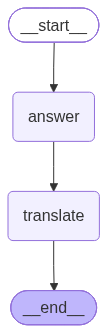

In [9]:
graph = parent_builder.compile()

graph

In [10]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': 'Quantum physics, also known as **quantum mechanics** or **quantum theory**, is a fundamental branch of physics that describes the behavior of matter and energy at the atomic and subatomic level.\n\nThink of it as the rulebook for the *really, really tiny* parts of our universe.\n\nHere\'s a breakdown of what that means:\n\n1.  **It Studies the Very Small:** Quantum physics deals with particles like electrons, protons, neutrons, photons (light particles), and even smaller, more exotic particles. It\'s the physics of atoms and everything inside them.\n\n2.  **It\'s Different from Classical Physics:**\n    *   **Classical Physics** (like Newton\'s laws) describes the world we experience daily: how a ball flies, how planets orbit, how cars move. It works great for large objects.\n    *   **Quantum Physics** steps in when things get incredibly small. At this scale, the rules change dramatically, and our everyday intuition often fails.\